In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, roc_auc_score

In [4]:
df = pd.read_csv("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# Convert TotalCharges from string to numeric, replacing empty spaces with NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')

# Impute missing values in TotalCharges using the column median
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# Drop unnecessary columns
df = df.drop(columns=['customerID'])

# Convert target variable 'Churn' from string labels Yes/No to binary integers 1/0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Check remaining nulls and print the class distribution
print("Remaining Missing Values per Column:\n", df.isnull().sum()[df.isnull().sum() > 0])
print(f"\nTarget Class Distribution (Proportions):\n{df['Churn'].value_counts(normalize=True)}")

Remaining Missing Values per Column:
 Series([], dtype: int64)

Target Class Distribution (Proportions):
Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64


In [6]:
# Separate predictor features X from target label y
X = df.drop(columns=['Churn'])
y = df['Churn']

# Identify categorical and numerical column names automatically
cat_cols = X.select_dtypes(include=['str']).columns.tolist()
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Build ColumnTransformer with OneHotEncoder for categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)

# Transform features into a clean NumPy array
X_processed = preprocessor.fit_transform(X)

# Get expanded feature names post-one-hot encoding for later interpretability
feature_names = num_cols + list(
    preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols)
)

# Train-test split (80/20) with stratification to preserve target distribution
X_train, X_test, y_train, y_test = train_test_split(
    X_processed, y, test_size=0.2, random_state=42, stratify=y
)

# Apply SMOTE to balance class counts ONLY on the training split
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# Calculate scale_pos_weight for XGBoost negative_count / positive_count
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

print(f"Original Training Balance: {dict(y_train.value_counts())}")
print(f"SMOTE Training Balance:    {dict(y_train_resampled.value_counts())}")
print(f"Calculated scale_pos_weight for XGBoost: {scale_pos_weight:.2f}")

Original Training Balance: {0: np.int64(4139), 1: np.int64(1495)}
SMOTE Training Balance:    {0: np.int64(4139), 1: np.int64(4139)}
Calculated scale_pos_weight for XGBoost: 2.77


In [7]:
# Initialize Stratified 5-Fold Cross-Validation scheme
cv_scheme = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Instantiate Random Forest Classifier (uses class_weight='balanced')
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Instantiate XGBoost Classifier (uses scale_pos_weight parameter)
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

# Evaluate Random Forest on non-resampled training data using 5-Fold CV
rf_cv_scores = cross_val_score(
    rf_model, X_train, y_train, cv=cv_scheme, scoring='roc_auc', n_jobs=-1
)

# Evaluate XGBoost on non-resampled training data using 5-Fold CV
xgb_cv_scores = cross_val_score(
    xgb_model, X_train, y_train, cv=cv_scheme, scoring='roc_auc', n_jobs=-1
)

# Fit final models on training data
rf_model.fit(X_train_resampled, y_train_resampled)  # Trained on SMOTE data
xgb_model.fit(X_train, y_train)                     # Trained using scale_pos_weight

print(f"Random Forest 5-Fold CV ROC-AUC: {rf_cv_scores.mean():.4f} (+- {rf_cv_scores.std():.4f})")
print(f"XGBoost       5-Fold CV ROC-AUC: {xgb_cv_scores.mean():.4f} (+- {xgb_cv_scores.std():.4f})")

Random Forest 5-Fold CV ROC-AUC: 0.8437 (+- 0.0098)
XGBoost       5-Fold CV ROC-AUC: 0.8449 (+- 0.0123)


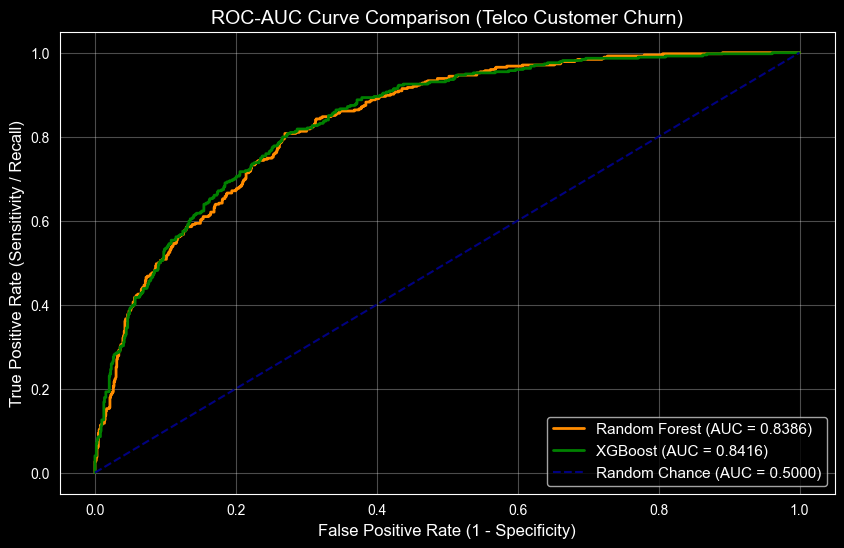

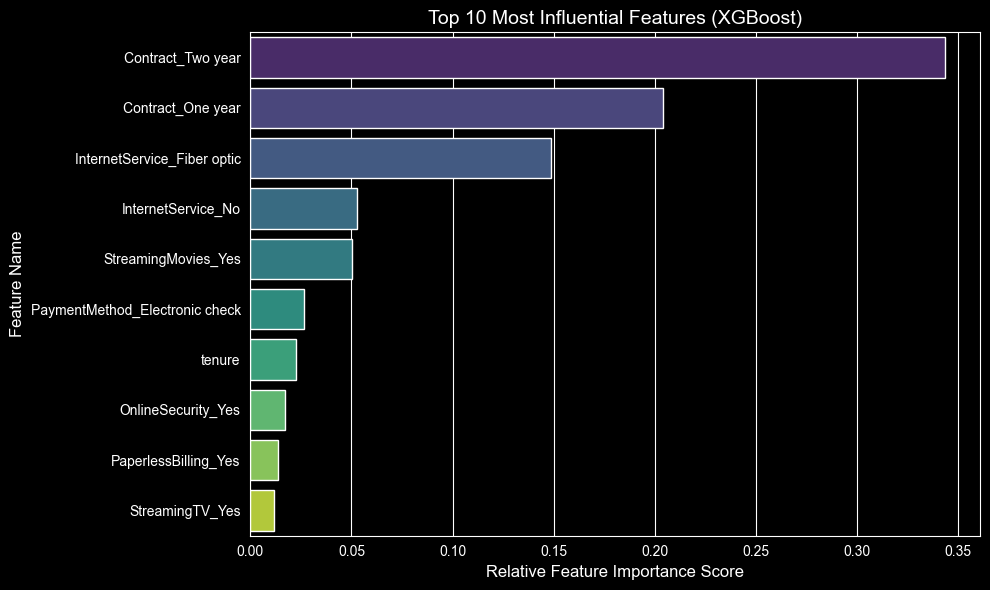

Final Test Set ROC-AUC Score (Random Forest): 0.8386
Final Test Set ROC-AUC Score (XGBoost):       0.8416


In [9]:
# Predict class probabilities for the held-out test set
rf_probs = rf_model.predict_proba(X_test)[:, 1]
xgb_probs = xgb_model.predict_proba(X_test)[:, 1]

# Compute ROC-AUC test set scores
rf_auc = roc_auc_score(y_test, rf_probs)
xgb_auc = roc_auc_score(y_test, xgb_probs)

# Compute False Positive Rate (FPR) and True Positive Rate (TPR) for ROC curve
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_probs)

# Plot ROC-AUC Curves side-by-side with reference line
plt.figure(figsize=(10, 6))
plt.plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {rf_auc:.4f})', color='darkorange', lw=2)
plt.plot(xgb_fpr, xgb_tpr, label=f'XGBoost (AUC = {xgb_auc:.4f})', color='green', lw=2)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--', label='Random Chance (AUC = 0.5000)')

plt.title('ROC-AUC Curve Comparison (Telco Customer Churn)', fontsize=14)
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12)
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)
plt.show()

# Extract and sort XGBoost feature importances
importances = xgb_model.feature_importances_
feature_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot Top 10 Most Influential Features
plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_imp_df.head(10),
    x='Importance',
    y='Feature',
    hue='Feature',      # Fix: Assign y-variable to hue
    legend=False,       # Fix: Disable duplicate legend
    palette='viridis'
)
plt.title('Top 10 Most Influential Features (XGBoost)', fontsize=14)
plt.xlabel('Relative Feature Importance Score', fontsize=12)
plt.ylabel('Feature Name', fontsize=12)
plt.tight_layout()
plt.show()

print(f"Final Test Set ROC-AUC Score (Random Forest): {rf_auc:.4f}")
print(f"Final Test Set ROC-AUC Score (XGBoost):       {xgb_auc:.4f}")